<h1 style="color:#1F4E79; font-size:40px; font-weight:700; text-align:center;">Business Insights</h1>

## **1: Import the libraries**

In [18]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from urllib.parse import quote_plus
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from adjustText import adjust_text

## **2: Load the database details from the .env file**

In [19]:
load_dotenv(find_dotenv())

password = quote_plus(os.getenv("DB_PASSWORD"))

## **3: Connect to MySQL**

In [20]:
engine = create_engine(
    f"mysql+pymysql://{os.getenv('DB_USER')}:{password}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

## **4. Test the connection**

In [21]:
pd.read_sql("SELECT COUNT(*) AS rows_in_pnl FROM pnl_sales", engine)

,rows_in_pnl
0,1425706


## **5. Charts**

#### Chart style

In [22]:
# Colours used across all charts
NAVY      = "#1F4E79"   # main colour
HIGHLIGHT = "#E07A1F"   # for the point each chart wants you to notice
GREY      = "#B0B7C3"   # for everything else
DARK_TEXT = "#334155"

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.labelcolor": DARK_TEXT,
    "axes.edgecolor": "#CBD5E1",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#E2E8F0",
    "xtick.color": DARK_TEXT,
    "ytick.color": DARK_TEXT,
    "legend.frameon": False,
})

CHARTS_DIR = "charts"
os.makedirs(CHARTS_DIR, exist_ok=True)

def save_chart(fig, file_name):
    """Save a chart as a high-resolution PNG in the charts folder."""
    fig.savefig(os.path.join(CHARTS_DIR, file_name), dpi=200, bbox_inches="tight")

### Chart 1: Net sales and gross margin % by year

In [23]:
query = """
SELECT
    fiscal_year,
    SUM(net_sales) / 1000000                    AS net_sales_mln,
    SUM(gross_margin) / SUM(net_sales) * 100    AS gm_pct
FROM pnl_sales
GROUP BY fiscal_year
ORDER BY fiscal_year
"""
pnl_by_year = pd.read_sql(query, engine)
pnl_by_year[["net_sales_mln", "gm_pct"]] = pnl_by_year[["net_sales_mln", "gm_pct"]].astype(float)
pnl_by_year

,fiscal_year,net_sales_mln,gm_pct
0,2018,29.112230,37.429875
1,2019,111.374287,41.202001
2,2020,267.978299,37.101055
3,2021,823.847433,36.490637
4,2022,1642.903587,37.746274


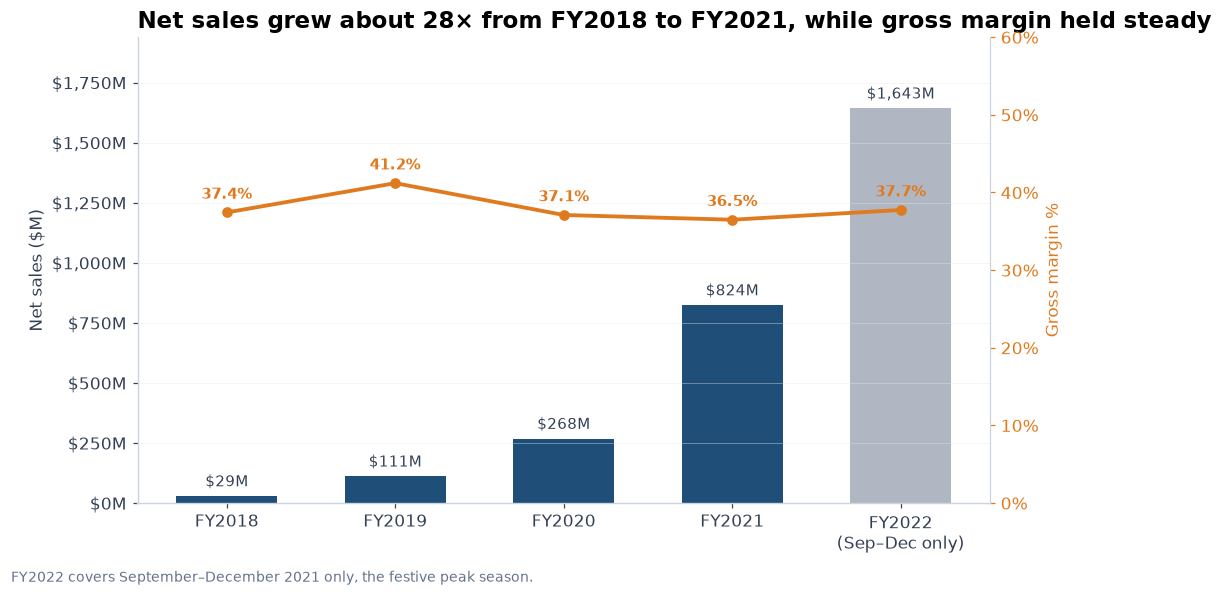

In [24]:
labels = [f"FY{y}" for y in pnl_by_year["fiscal_year"]]
labels[-1] = "FY2022\n(Sep–Dec only)"
bar_colours = [NAVY] * (len(pnl_by_year) - 1) + [GREY]

fig, ax = plt.subplots()

# Bars: net sales
bars = ax.bar(labels, pnl_by_year["net_sales_mln"], color=bar_colours, width=0.6)
ax.bar_label(bars, labels=[f"${v:,.0f}M" for v in pnl_by_year["net_sales_mln"]],
             padding=4, fontsize=10, color=DARK_TEXT)
ax.set_ylabel("Net sales ($M)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
ax.set_ylim(0, pnl_by_year["net_sales_mln"].max() * 1.18)

# Line: gross margin % on a second axis
ax2 = ax.twinx()
ax2.plot(labels, pnl_by_year["gm_pct"], color=HIGHLIGHT, marker="o", linewidth=2.5)
for x, y in zip(labels, pnl_by_year["gm_pct"]):
    ax2.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=10, color=HIGHLIGHT, fontweight="bold")
ax2.set_ylim(0, 60)
ax2.set_ylabel("Gross margin %", color=HIGHLIGHT)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.tick_params(axis="y", colors=HIGHLIGHT)

ax.set_title("Net sales grew about 28× from FY2018 to FY2021, while gross margin held steady")
fig.text(0.01, -0.02, "FY2022 covers September–December 2021 only, the festive peak season.",
         fontsize=9, color="#64748B")

save_chart(fig, "01_net_sales_and_gross_margin.png")
plt.show()

### Business insights - Chart 1

- **Rapid growth:** Net sales rose from USD 29M in FY2018 to USD 111M in FY2019, USD 268M in FY2020 and USD 824M in FY2021, more than doubling every year and growing about 28 times in three years.
- **Stable profitability:** Gross margin stayed between about 36% and 41% in every year, so AtliQ grew quickly without giving up margin.
- **FY2022 is only part of a year:** The grey bar covers September–December 2021 only, AtliQ's peak season, so it can't be compared directly with the full years.

**What it means:** AtliQ is growing very fast while keeping its profitability steady.

### Chart 2: Product mix by year

In [25]:
query = """
SELECT
    fiscal_year,
    segment,
    SUM(net_sales) / SUM(SUM(net_sales)) OVER (PARTITION BY fiscal_year) * 100 AS share_pct
FROM pnl_sales
GROUP BY fiscal_year, segment
"""
mix = pd.read_sql(query, engine)
mix["share_pct"] = mix["share_pct"].astype(float)

# One row per year, one column per segment
mix_table = mix.pivot(index="fiscal_year", columns="segment", values="share_pct").fillna(0)

segment_order = ["Notebook", "Desktop", "Peripherals", "Accessories", "Storage", "Networking"]
mix_table = mix_table[segment_order]
mix_table.round(1)

segment,Notebook,Desktop,Peripherals,Accessories,Storage,Networking
fiscal_year,,,,,,
2018,25.5,0.0,26.1,30.8,6.5,11.1
2019,29.1,0.0,17.7,25.2,12.4,15.6
2020,32.2,0.4,22.6,24.7,10.3,9.8
2021,32.3,5.6,20.2,29.7,6.6,5.5
2022,41.6,17.1,27.1,11.6,1.6,1.0


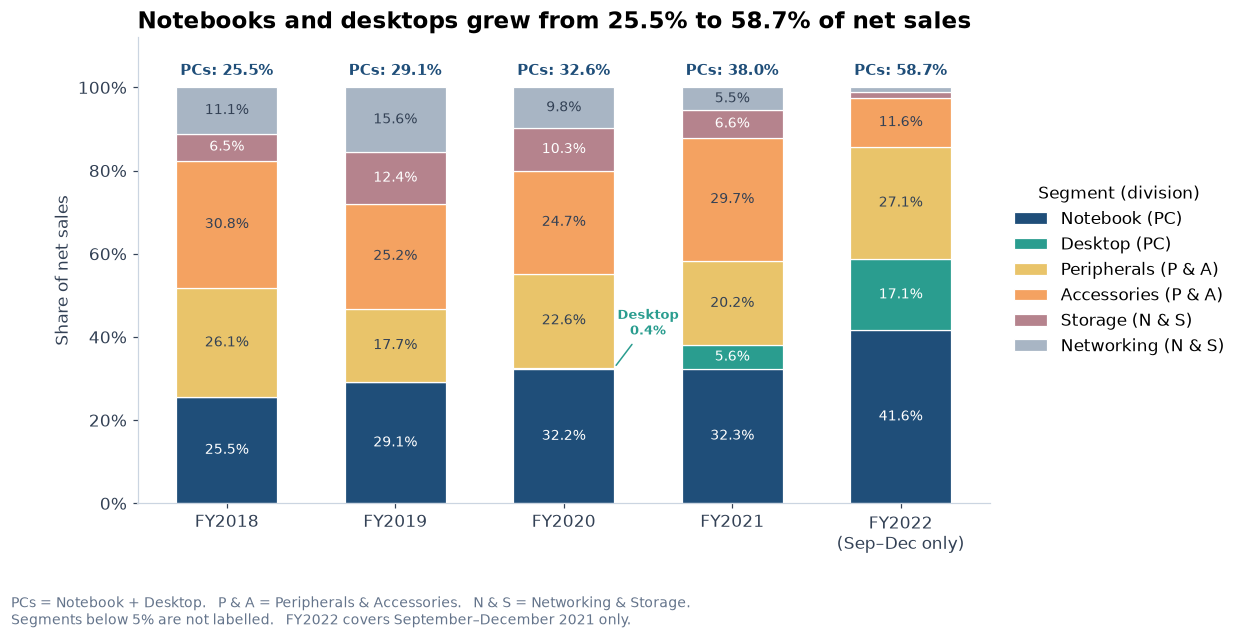

In [26]:
segment_colours = {
    "Notebook":    "#1F4E79",   # deep navy   (PC, strong)
    "Desktop":     "#2A9D8F",   # teal        (PC, strong)
    "Peripherals": "#E9C46A",   # soft yellow
    "Accessories": "#F4A261",   # light orange
    "Storage":     "#B5838D",   # dusty rose
    "Networking":  "#A8B5C4",   # cool grey
}

# Division each segment belongs to, shown in the legend
segment_division = {
    "Notebook":    "PC",
    "Desktop":     "PC",
    "Peripherals": "P & A",
    "Accessories": "P & A",
    "Storage":     "N & S",
    "Networking":  "N & S",
}

labels = [f"FY{y}" for y in mix_table.index]
labels[-1] = "FY2022\n(Sep–Dec only)"

fig, ax = plt.subplots()
bottom = [0] * len(mix_table)

for segment in segment_order:
    values = mix_table[segment].values
    bars = ax.bar(labels, values, bottom=bottom, color=segment_colours[segment],
                  width=0.6, label=f"{segment} ({segment_division[segment]})",
                  edgecolor="white", linewidth=0.8)
    # Label a segment only if it's big enough to fit the text
    text_colour = "white" if segment in ("Notebook", "Desktop", "Storage") else DARK_TEXT
    ax.bar_label(bars, labels=[f"{v:.1f}%" if v >= 5 else "" for v in values],
                 label_type="center", fontsize=9, color=text_colour)
    bottom = [b + v for b, v in zip(bottom, values)]

# Combined PC share above each bar
pc_share = mix_table["Notebook"] + mix_table["Desktop"]
for x, share in zip(labels, pc_share):
    ax.text(x, 103, f"PCs: {share:.1f}%", ha="center", fontsize=10,
            fontweight="bold", color=NAVY)

# Point out the tiny FY2020 desktop share, which is too thin to see
fy2020 = list(mix_table.index).index(2020)
desktop_top = mix_table.loc[2020, "Notebook"] + mix_table.loc[2020, "Desktop"]
ax.annotate(f"Desktop\n{mix_table.loc[2020, 'Desktop']:.1f}%",
            xy=(fy2020 + 0.3, desktop_top),
            xytext=(fy2020 + 0.5, desktop_top + 8),
            ha="center", fontsize=8.5, color="#2A9D8F", fontweight="bold",
            arrowprops=dict(arrowstyle="-", color="#2A9D8F", lw=1))

ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 20))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Share of net sales")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Segment (division)")
ax.grid(False)

ax.set_title("Notebooks and desktops grew from 25.5% to 58.7% of net sales")
fig.text(0.01, -0.09,
         "PCs = Notebook + Desktop.   P & A = Peripherals & Accessories.   N & S = Networking & Storage.\n"
         "Segments below 5% are not labelled.   FY2022 covers September–December 2021 only.",
         fontsize=9, color="#64748B")

save_chart(fig, "02_product_mix_by_year.png")
plt.show()

### Business insights - Chart 2

- **PCs took over the sales mix:** Notebooks and desktops (the PC division) grew from 25.5% of net sales in FY2018 to 29.1% in FY2019, 32.6% in FY2020, 38.0% in FY2021 and 58.7% in September–December 2021.
- **Notebooks lead:** Notebooks became the largest segment, reaching 41.6% of net sales in September–December 2021.
- **Desktops appeared from almost nothing:** Desktops had almost no sales in FY2018, none in FY2019 and only 0.4% in FY2020, then grew to 5.6% in FY2021 and 17.1% in September–December 2021.
- **Lower-value segments lost share:** Accessories fell from 29.7% in FY2021 to 11.6% in September–December 2021, while storage and networking shrank to below 5% each.

**What it means:** AtliQ's sales are moving strongly towards higher-value PCs, so each unit sold brings in more revenue than before.

### Chart 3: Monthly net sales, FY2021

In [27]:
query = """
SELECT
    date,
    SUM(net_sales) / 1000000 AS net_sales_mln
FROM pnl_sales
WHERE fiscal_year = 2021
GROUP BY date
ORDER BY date
"""
monthly = pd.read_sql(query, engine)
monthly["net_sales_mln"] = monthly["net_sales_mln"].astype(float)
monthly["month"] = pd.to_datetime(monthly["date"]).dt.strftime("%b %Y")
monthly

,date,net_sales_mln,month
0,2020-09-01,60.286839,Sep 2020
1,2020-10-01,75.850003,Oct 2020
2,2020-11-01,102.270154,Nov 2020
3,2020-12-01,108.405472,Dec 2020
4,2021-01-01,60.141434,Jan 2021
5,2021-02-01,58.076879,Feb 2021
6,2021-03-01,60.364342,Mar 2021
7,2021-04-01,60.488464,Apr 2021
8,2021-05-01,59.784815,May 2021
9,2021-06-01,57.716901,Jun 2021


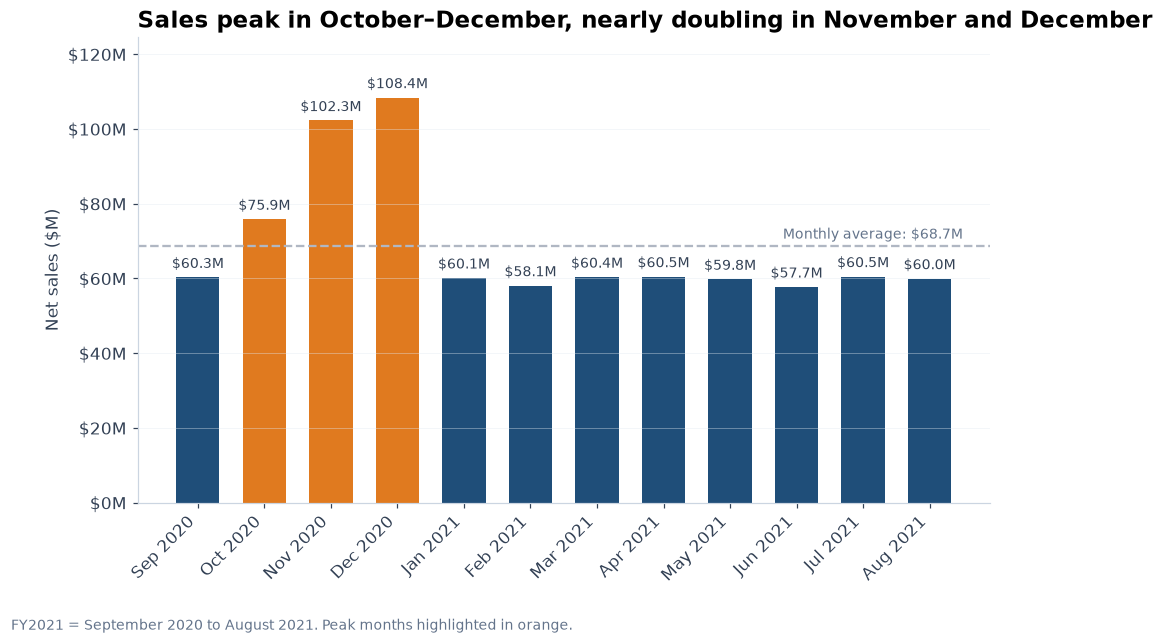

In [28]:
peak_months = ["Oct 2020", "Nov 2020", "Dec 2020"]
bar_colours = [HIGHLIGHT if m in peak_months else NAVY for m in monthly["month"]]

fig, ax = plt.subplots()
bars = ax.bar(monthly["month"], monthly["net_sales_mln"], color=bar_colours, width=0.65)
ax.bar_label(bars, labels=[f"${v:,.1f}M" for v in monthly["net_sales_mln"]],
             padding=4, fontsize=9, color=DARK_TEXT)

# Average month, as a reference line
average = monthly["net_sales_mln"].mean()
ax.axhline(average, color=GREY, linestyle="--", linewidth=1.5)
ax.text(len(monthly) - 0.5, average + 2, f"Monthly average: ${average:,.1f}M",
        ha="right", fontsize=9, color="#64748B")

ax.set_ylabel("Net sales ($M)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
ax.set_ylim(0, monthly["net_sales_mln"].max() * 1.15)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_title("Sales peak in October–December, nearly doubling in November and December")
fig.text(0.01, -0.1, "FY2021 = September 2020 to August 2021. Peak months highlighted in orange.",
         fontsize=9, color="#64748B")

save_chart(fig, "03_monthly_net_sales_fy2021.png")
plt.show()

### Business insights - Chart 3

- **A clear festive peak:** Net sales rose from USD 60.3M in September 2020 to USD 75.9M in October, then USD 102.3M in November and USD 108.4M in December, the strongest month of the year.
- **Nearly double a normal month:** Outside the peak, monthly sales were very steady at about USD 58–61M. November and December were roughly 1.7–1.8 times that level.
- **Three months carry a large share of the year:** October to December together brought in about USD 287M, around 35% of FY2021's net sales in just a quarter of the year.
- **Most months are below average:** The monthly average of about USD 68.7M is pulled up by the peak, so 9 of the 12 months sit below it.

**What it means:** AtliQ's demand is strongly seasonal. Production, stock and forecasts need to be ready ahead of October–December, when sales nearly double.

### Chart 4: Markets: net sales vs gross margin %, FY2021

In [29]:
query = """
SELECT
    market_name,
    SUM(net_sales) / 1000000                 AS net_sales_mln,
    SUM(gross_margin) / SUM(net_sales) * 100 AS gm_pct
FROM pnl_sales
WHERE fiscal_year = 2021
GROUP BY market_name
"""
markets = pd.read_sql(query, engine)
markets[["net_sales_mln", "gm_pct"]] = markets[["net_sales_mln", "gm_pct"]].astype(float)

company = pd.read_sql("""
SELECT SUM(gross_margin) / SUM(net_sales) * 100 AS gm_pct
FROM pnl_sales
WHERE fiscal_year = 2021
""", engine)
company_gm = float(company["gm_pct"].iloc[0])

markets.sort_values("net_sales_mln", ascending=False)

,market_name,net_sales_mln,gm_pct
0,India,210.671644,32.029075
16,USA,132.049292,36.890523
5,South Korea,64.010019,35.940539
17,Canada,45.890889,38.222389
23,United Kingdom,44.730672,45.131557
4,Philippines,41.879713,39.135975
9,France,37.819741,43.592336
19,China,29.873651,41.100002
6,Australia,27.597532,32.938978
1,Indonesia,24.240945,38.461357


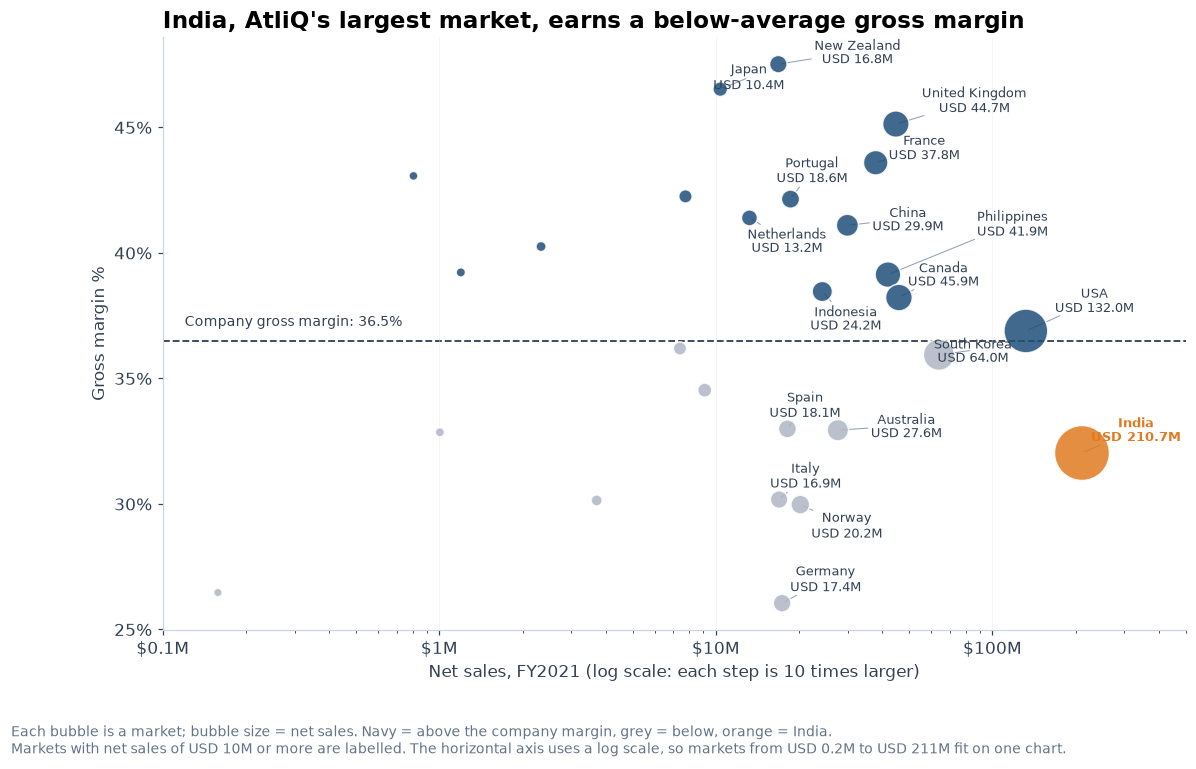

In [30]:
# Colour: India highlighted, others by above/below the company margin
def market_colour(row):
    if row["market_name"] == "India":
        return HIGHLIGHT
    return NAVY if row["gm_pct"] >= company_gm else GREY

colours = markets.apply(market_colour, axis=1)
sizes = markets["net_sales_mln"] * 6 + 30   # bubble size grows with net sales

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(markets["net_sales_mln"], markets["gm_pct"], s=sizes, c=colours,
           alpha=0.85, edgecolors="white", linewidth=1, zorder=2)

# Company average margin
ax.axhline(company_gm, color=DARK_TEXT, linestyle="--", linewidth=1.2, zorder=1)
ax.text(0.12, company_gm + 0.6, f"Company gross margin: {company_gm:.1f}%",
        fontsize=9, color=DARK_TEXT)

# Log scale on net sales, with clear x10 steps (set before placing labels)
ax.set_xscale("log")
ax.set_xticks([0.1, 1, 10, 100])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}M" if x >= 1 else f"${x:.1f}M"))
ax.set_xlim(0.1, 500)
ax.set_xlabel("Net sales, FY2021 (log scale: each step is 10 times larger)")

ax.set_ylabel("Gross margin %")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="both")

# Label every market with at least USD 10M of net sales: name and amount
to_label = markets[markets["net_sales_mln"] >= 10]
texts = []
for _, row in to_label.iterrows():
    is_india = row["market_name"] == "India"
    texts.append(ax.text(row["net_sales_mln"], row["gm_pct"],
                         f"{row['market_name']}\nUSD {row['net_sales_mln']:,.1f}M",
                         fontsize=8.5, linespacing=1.1, zorder=3,
                         color=HIGHLIGHT if is_india else DARK_TEXT,
                         fontweight="bold" if is_india else "normal"))

# Move labels apart automatically so none overlap each other or the bubbles
adjust_text(texts,
            x=markets["net_sales_mln"].values, y=markets["gm_pct"].values,
            ax=ax,
            expand=(1.3, 1.6),
            arrowprops=dict(arrowstyle="-", color="#94A3B8", lw=0.7))

ax.set_title("India, AtliQ's largest market, earns a below-average gross margin")
fig.text(0.01, -0.05,
         "Each bubble is a market; bubble size = net sales. Navy = above the company margin, grey = below, orange = India.\n"
         "Markets with net sales of USD 10M or more are labelled. The horizontal axis uses a log scale, "
         "so markets from USD 0.2M to USD 211M fit on one chart.",
         fontsize=9, color="#64748B")

save_chart(fig, "04_markets_sales_vs_margin.png")
plt.show()

### Business insights - Chart 4

- **The largest market earns a below-average margin:** India, AtliQ's biggest market at USD 210.7M, sits clearly below the company's gross margin of 36.5%, at about 32%.
- **The other big markets sit close to the average:** The USA (USD 132.1M) is just above the company line, and South Korea (USD 64.0M) just below it.
- **The highest margins come from smaller markets:** New Zealand (USD 16.8M), Japan (USD 10.4M) and the United Kingdom (USD 44.7M) reach about 45–48%, well above the company average.
- **Germany is the weakest sizeable market:** At USD 17.4M of net sales, it has the lowest margin of the labelled markets, at about 26%.
- **Profitability doesn't follow size:** Navy (above-average) and grey (below-average) bubbles appear across all market sizes, so being large doesn't make a market more profitable.

**What it means:** AtliQ's overall margin depends heavily on India. Improving profitability there, for example by reviewing discounts and costs, would lift the whole company more than growing its smaller, high-margin markets.

### Chart 5: Forecast accuracy and net error by year

In [31]:
query = """
SELECT
    fiscal_year,
    SUM(net_error) / SUM(forecast_qty) * 100                    AS net_error_pct,
    GREATEST(0, 100 - SUM(abs_error) / SUM(forecast_qty) * 100) AS accuracy_pct
FROM forecast_vs_actual
GROUP BY fiscal_year
ORDER BY fiscal_year
"""
accuracy = pd.read_sql(query, engine)
accuracy[["net_error_pct", "accuracy_pct"]] = accuracy[["net_error_pct", "accuracy_pct"]].astype(float)
accuracy

,fiscal_year,net_error_pct,accuracy_pct
0,2018,16.41,39.32
1,2019,5.58,41.32
2,2020,2.31,25.73
3,2021,-1.52,39.03
4,2022,-9.48,37.23


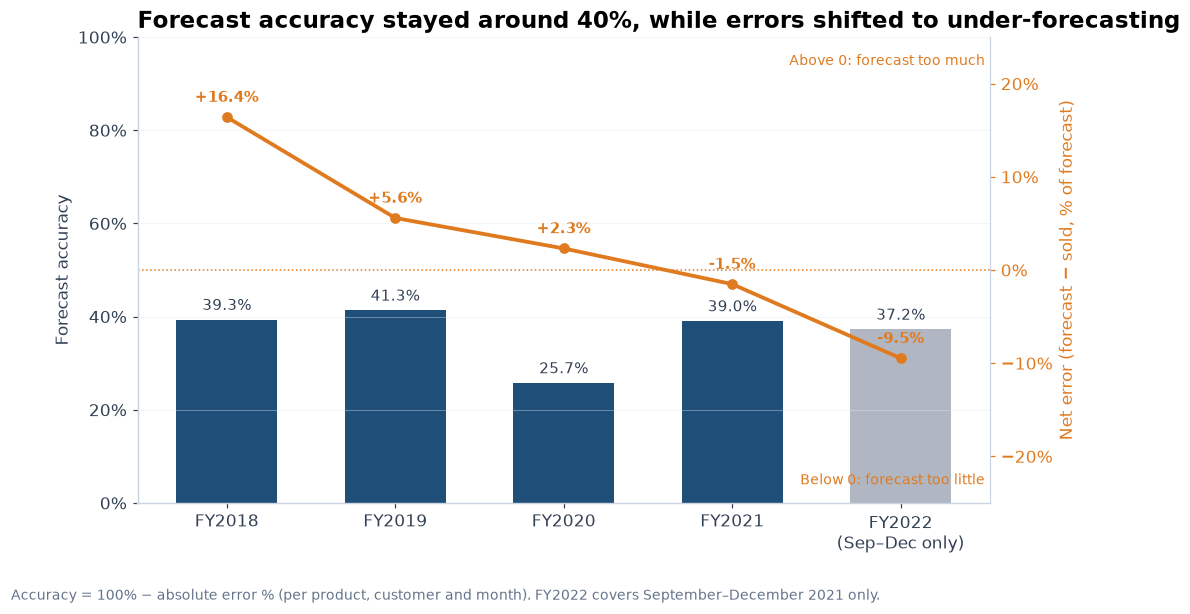

In [32]:
labels = [f"FY{y}" for y in accuracy["fiscal_year"]]
labels[-1] = "FY2022\n(Sep–Dec only)"
bar_colours = [NAVY] * (len(accuracy) - 1) + [GREY]

fig, ax = plt.subplots()

# Bars: forecast accuracy
bars = ax.bar(labels, accuracy["accuracy_pct"], color=bar_colours, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in accuracy["accuracy_pct"]],
             padding=4, fontsize=10, color=DARK_TEXT)
ax.set_ylim(0, 100)
ax.set_ylabel("Forecast accuracy")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# Line: net error % on a second axis, with a zero line
ax2 = ax.twinx()
ax2.axhline(0, color=HIGHLIGHT, linewidth=1, linestyle=":")
ax2.plot(labels, accuracy["net_error_pct"], color=HIGHLIGHT, marker="o", linewidth=2.5)
for x, y in zip(labels, accuracy["net_error_pct"]):
    ax2.annotate(f"{y:+.1f}%", (x, y), textcoords="offset points",
                 xytext=(0, 10), ha="center",
                 fontsize=10, color=HIGHLIGHT, fontweight="bold")
ax2.set_ylim(-25, 25)
ax2.set_ylabel("Net error (forecast − sold, % of forecast)", color=HIGHLIGHT)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.tick_params(axis="y", colors=HIGHLIGHT)
ax2.grid(False)
ax2.spines["right"].set_visible(True)

# Labels explaining what above and below zero mean
ax2.text(len(labels) - 0.5, 22, "Above 0: forecast too much", ha="right",
         fontsize=9, color=HIGHLIGHT)
ax2.text(len(labels) - 0.5, -23, "Below 0: forecast too little", ha="right",
         fontsize=9, color=HIGHLIGHT)

ax.set_title("Forecast accuracy stayed around 40%, while errors shifted to under-forecasting")
fig.text(0.01, -0.05,
         "Accuracy = 100% − absolute error % (per product, customer and month). "
         "FY2022 covers September–December 2021 only.",
         fontsize=9, color="#64748B")

save_chart(fig, "05_forecast_accuracy_by_year.png")
plt.show()

### Business insights - Chart 5

- **Accuracy stayed low:** Forecast accuracy was 39.3% in FY2018, 41.3% in FY2019, 25.7% in FY2020, 39.0% in FY2021 and 37.2% in September–December 2021, so forecasts were off by about 60% in most years, with no improvement over time.
- **FY2020 was the worst year:** Accuracy dropped to 25.7%, the lowest of all years.
- **Errors changed direction:** The net error moved from +16.4% in FY2018 (forecasting too much) through +5.6%, +2.3% and −1.5%, to −9.5% in September–December 2021 (forecasting too little).
- **A small net error can hide large mistakes:** In FY2021, the net error was only −1.5%, yet accuracy was just 39.0%, because forecasts that were too high and too low cancelled each other out in the total.

**What it means:** AtliQ's forecasts are not keeping up with its growth. Early on, it planned for more than it sold; now it plans for less, which increasingly puts sales at risk of stock-outs.

### Chart 6: The cost of forecast errors by year

In [33]:
query = """
WITH pnl AS (
    SELECT fiscal_year,
           SUM(net_sales)    AS net_sales,
           SUM(gross_margin) AS gross_margin
    FROM pnl_sales
    GROUP BY fiscal_year
),
costs AS (
    SELECT fiscal_year,
           SUM(holding_cost_1pct) AS holding_1,
           SUM(holding_cost_2pct) AS holding_2,
           SUM(holding_cost_3pct) AS holding_3,
           SUM(revenue_at_risk)   AS revenue_at_risk
    FROM cost_of_errors
    GROUP BY fiscal_year
)
SELECT
    p.fiscal_year,
    c.holding_1 / p.net_sales * 100                                  AS holding_1_pct,
    c.holding_2 / p.net_sales * 100                                  AS holding_2_pct,
    c.holding_3 / p.net_sales * 100                                  AS holding_3_pct,
    c.revenue_at_risk * (p.gross_margin / p.net_sales) / p.net_sales * 100 AS margin_at_risk_pct,
    c.holding_2 / 1000000                                            AS holding_2_mln,
    c.revenue_at_risk * (p.gross_margin / p.net_sales) / 1000000     AS margin_at_risk_mln
FROM pnl AS p
JOIN costs AS c
    ON p.fiscal_year = c.fiscal_year
ORDER BY p.fiscal_year
"""
error_costs = pd.read_sql(query, engine)
number_columns = ["holding_1_pct", "holding_2_pct", "holding_3_pct",
                  "margin_at_risk_pct", "holding_2_mln", "margin_at_risk_mln"]
error_costs[number_columns] = error_costs[number_columns].astype(float)
error_costs.round(2)

,fiscal_year,holding_1_pct,holding_2_pct,holding_3_pct,margin_at_risk_pct,holding_2_mln,margin_at_risk_mln
0,2018,0.60,1.20,1.80,1.82,0.35,0.53
1,2019,0.58,1.16,1.74,1.91,1.29,2.13
2,2020,0.75,1.49,2.24,2.21,4.00,5.92
3,2021,0.76,1.52,2.29,2.65,12.55,21.84
4,2022,0.18,0.36,0.54,3.50,5.93,57.49


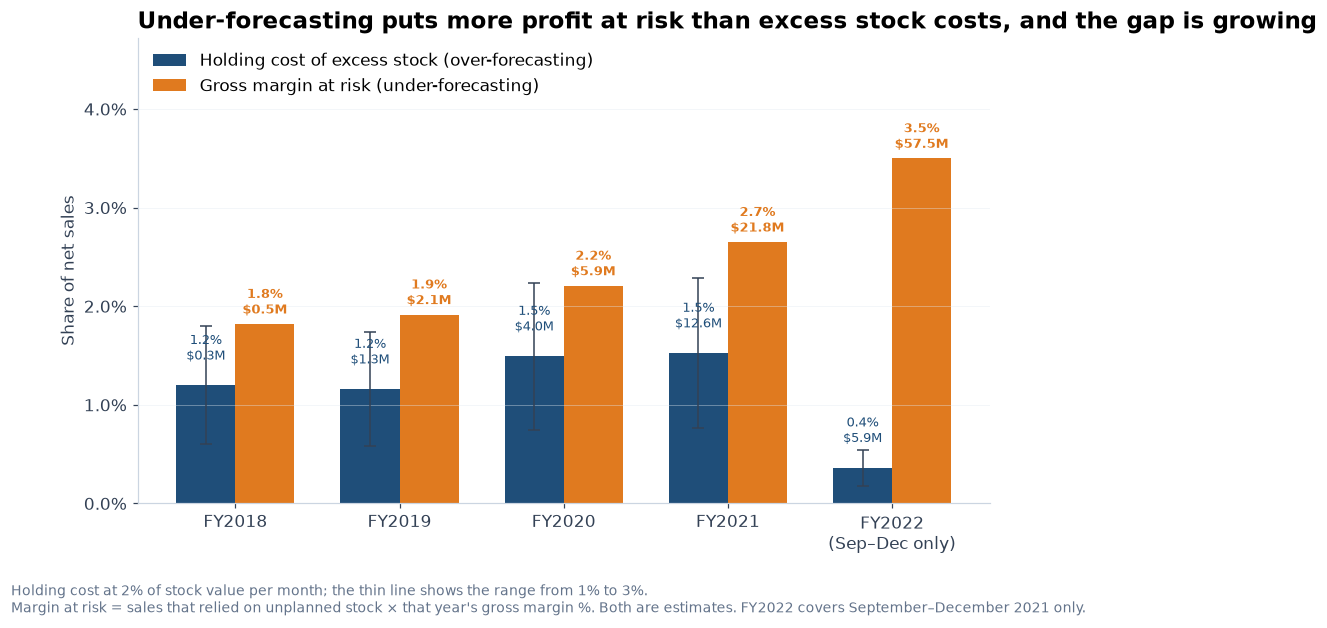

In [35]:
labels = [f"FY{y}" for y in error_costs["fiscal_year"]]
labels[-1] = "FY2022\n(Sep–Dec only)"
positions = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots()

# Holding cost bars (2%), with a thin line showing the 1%–3% range
holding_bars = ax.bar(positions - width / 2, error_costs["holding_2_pct"], width,
                      color=NAVY, label="Holding cost of excess stock (over-forecasting)")
ax.errorbar(positions - width / 2, error_costs["holding_2_pct"],
            yerr=[error_costs["holding_2_pct"] - error_costs["holding_1_pct"],
                  error_costs["holding_3_pct"] - error_costs["holding_2_pct"]],
            fmt="none", ecolor=DARK_TEXT, elinewidth=1, capsize=4)

# Margin at risk bars
risk_bars = ax.bar(positions + width / 2, error_costs["margin_at_risk_pct"], width,
                   color=HIGHLIGHT, label="Gross margin at risk (under-forecasting)")

# Value labels: share of net sales and the amount in millions
ax.bar_label(holding_bars,
             labels=[f"{p:.1f}%\n${m:,.1f}M" for p, m in
                     zip(error_costs["holding_2_pct"], error_costs["holding_2_mln"])],
             padding=14, fontsize=8.5, color=NAVY)
ax.bar_label(risk_bars,
             labels=[f"{p:.1f}%\n${m:,.1f}M" for p, m in
                     zip(error_costs["margin_at_risk_pct"], error_costs["margin_at_risk_mln"])],
             padding=4, fontsize=8.5, color=HIGHLIGHT, fontweight="bold")

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylim(0, error_costs["margin_at_risk_pct"].max() * 1.35)
ax.set_ylabel("Share of net sales")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.legend(loc="upper left")

ax.set_title("Under-forecasting puts more profit at risk than excess stock costs, and the gap is growing")
fig.text(0.01, -0.07,
         "Holding cost at 2% of stock value per month; the thin line shows the range from 1% to 3%.\n"
         "Margin at risk = sales that relied on unplanned stock × that year's gross margin %. "
         "Both are estimates. FY2022 covers September–December 2021 only.",
         fontsize=9, color="#64748B")

save_chart(fig, "06_cost_of_forecast_errors.png")
plt.show()

### Business insights - Chart 6

- **Under-forecasting puts more profit at risk:** In every year, the gross margin at risk from forecasting too little (orange) is higher than the holding cost of excess stock at the 2% rate (navy).
- **The risk is growing:** Margin at risk rose from 1.8% of net sales in FY2018 to 2.7% (USD 21.8M) in FY2021 and 3.5% (USD 57.5M) in September–December 2021.
- **Holding cost stayed fairly stable:** The cost of excess stock remained around 1.2–1.5% of net sales (USD 12.6M in FY2021). Its lower share in September–December 2021 (0.4%) reflects four months of holding cost against the very high peak-season sales.
- **The conclusion holds even if holding stock costs more:** The black line on each navy bar shows how the holding cost would change if keeping stock cost 1% or 3% of its value per month instead of 2%. In FY2021, even the top of that line stays below the orange bar, so under-forecasting remains the bigger risk.

**What it means:** Both kinds of forecast error cost AtliQ money, but forecasting too little is the bigger and growing problem. Improving forecasts for fast-growing customers and markets would protect the most profit.

### Chart 7: Discount leakage among the top customers

In [36]:
query = """
SELECT
    customer,
    SUM(gross_sales) / 1000000                                                   AS gross_sales_mln,
    (SUM(pre_invoice_deductions) + SUM(post_invoice_deductions)) / SUM(gross_sales) * 100 AS deductions_pct,
    SUM(gross_margin) / SUM(net_sales) * 100                                      AS gm_pct
FROM pnl_sales
WHERE fiscal_year = 2021
GROUP BY customer
ORDER BY SUM(gross_sales) DESC
LIMIT 10
"""
customers = pd.read_sql(query, engine)
customers[["gross_sales_mln", "deductions_pct", "gm_pct"]] = \
    customers[["gross_sales_mln", "deductions_pct", "gm_pct"]].astype(float)
customers.round(2)

,customer,gross_sales_mln,deductions_pct,gm_pct
0,Amazon,224.26,51.38,35.40
1,Atliq Exclusive,142.21,43.80,43.73
2,Atliq e Store,139.85,49.72,37.54
3,Sage,56.38,51.98,35.16
4,Flipkart,56.17,55.04,30.23
5,Leader,52.03,52.89,34.01
6,Ebay,40.28,50.65,36.10
7,Neptune,38.83,45.90,41.18
8,Electricalsocity,33.63,51.67,34.83
9,Synthetic,30.93,47.95,39.25


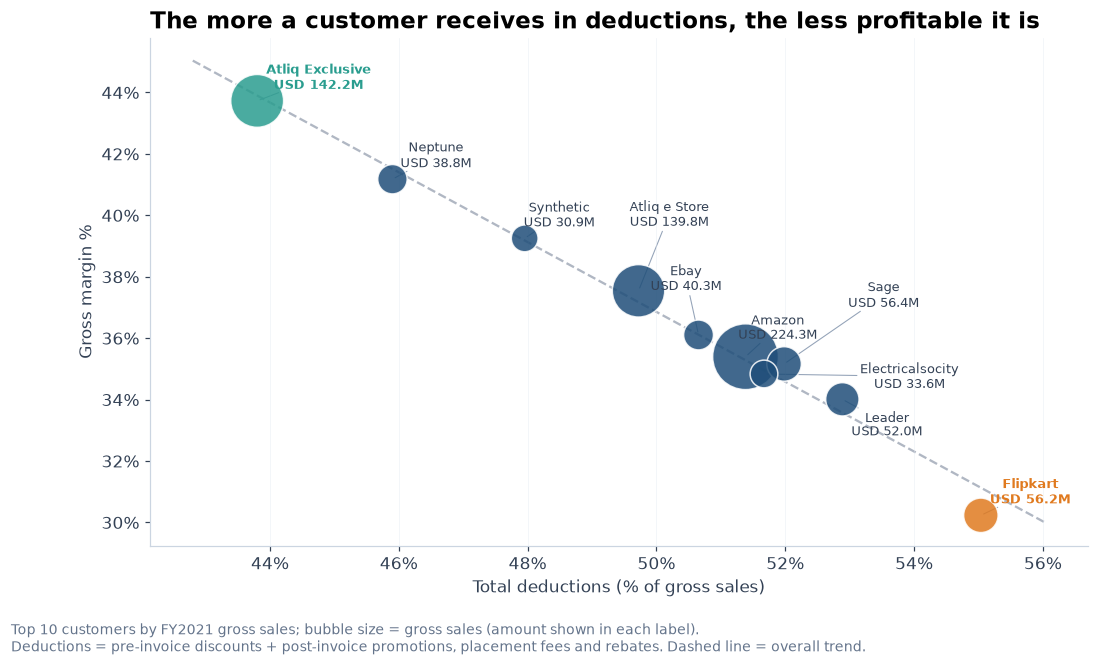

In [37]:
import numpy as np

highlight_customers = {"Flipkart": HIGHLIGHT, "Atliq Exclusive": "#2A9D8F"}
colours = [highlight_customers.get(c, NAVY) for c in customers["customer"]]
sizes = customers["gross_sales_mln"] * 8 + 60   # bubble size = gross sales

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(customers["deductions_pct"], customers["gm_pct"], s=sizes, c=colours,
           alpha=0.85, edgecolors="white", linewidth=1, zorder=2)

# Trend line, showing the overall relationship
slope, intercept = np.polyfit(customers["deductions_pct"], customers["gm_pct"], 1)
x_line = np.linspace(customers["deductions_pct"].min() - 1, customers["deductions_pct"].max() + 1, 50)
ax.plot(x_line, slope * x_line + intercept, color=GREY, linestyle="--", linewidth=1.5, zorder=1)

# Labels, arranged automatically so they don't overlap
texts = []
for _, row in customers.iterrows():
    colour = highlight_customers.get(row["customer"], DARK_TEXT)
    is_highlight = row["customer"] in highlight_customers
    texts.append(ax.text(row["deductions_pct"], row["gm_pct"],
                         f"{row['customer']}\nUSD {row['gross_sales_mln']:,.1f}M",
                         fontsize=8.5, linespacing=1.1, zorder=3, color=colour,
                         fontweight="bold" if is_highlight else "normal"))
adjust_text(texts, x=customers["deductions_pct"].values, y=customers["gm_pct"].values,
            ax=ax, expand=(1.3, 1.6),
            arrowprops=dict(arrowstyle="-", color="#94A3B8", lw=0.7))

ax.set_xlabel("Total deductions (% of gross sales)")
ax.set_ylabel("Gross margin %")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="both")

ax.set_title("The more a customer receives in deductions, the less profitable it is")
fig.text(0.01, -0.05,
         "Top 10 customers by FY2021 gross sales; bubble size = gross sales (amount shown in each label).\n"
         "Deductions = pre-invoice discounts + post-invoice promotions, placement fees and rebates. "
         "Dashed line = overall trend.",
         fontsize=9, color="#64748B")

save_chart(fig, "07_discount_leakage_top_customers.png")
plt.show()

### Business insights - Chart 7

- **More deductions, lower margin:** The trend line slopes clearly downwards: the more a customer receives back in discounts, promotions, placement fees and rebates, the less profitable it is for AtliQ.
- **Flipkart is the least profitable large customer:** It receives the most in deductions (about 55% of gross sales) and has the lowest margin, about 30%.
- **AtliQ's own stores are the most profitable:** Atliq Exclusive (USD 142.2M of gross sales) receives the least in deductions (about 44%) and has the highest margin (about 44%).
- **The biggest customer sits in the middle:** Amazon, by far the largest customer (USD 224.3M of gross sales), receives about 51% in deductions, for a margin of about 35%.
- **Lower deductions pay off:** Neptune (USD 38.8M) shows that a customer with relatively low deductions (about 46%) can be among the most profitable, at about 41%.

**What it means:** Customer profitability depends heavily on the discount and rebate terms each customer receives. Reviewing the agreements with high-deduction customers such as Flipkart is one of the clearest ways for AtliQ to improve its margin.

### Chart 8: Forecast accuracy by market, FY2021

In [38]:
query = """
SELECT
    market_name,
    SUM(forecast_qty)                                           AS forecast_units,
    SUM(net_error) / SUM(forecast_qty) * 100                    AS net_error_pct,
    GREATEST(0, 100 - SUM(abs_error) / SUM(forecast_qty) * 100) AS accuracy_pct
FROM forecast_vs_actual
WHERE fiscal_year = 2021
GROUP BY market_name
ORDER BY accuracy_pct
"""
market_accuracy = pd.read_sql(query, engine)
market_accuracy[["forecast_units", "net_error_pct", "accuracy_pct"]] = \
    market_accuracy[["forecast_units", "net_error_pct", "accuracy_pct"]].astype(float)

company_accuracy = pd.read_sql("""
SELECT GREATEST(0, 100 - SUM(abs_error) / SUM(forecast_qty) * 100) AS accuracy_pct
FROM forecast_vs_actual
WHERE fiscal_year = 2021
""", engine)
company_accuracy = float(company_accuracy["accuracy_pct"].iloc[0])

market_accuracy.round(2)

,market_name,forecast_units,net_error_pct,accuracy_pct
0,Netherlands,411548.0,-78.41,0.00
1,South Korea,2654995.0,-48.69,18.32
2,Sweden,95353.0,-42.64,19.77
3,Germany,868951.0,-43.14,21.09
4,Philippines,1762988.0,-37.42,25.37
5,Japan,415495.0,-27.44,30.61
6,Poland,359416.0,-21.02,34.12
7,Mexico,58674.0,-21.37,34.42
8,USA,6752124.0,-17.77,35.35
9,Pakistan,404157.0,-12.43,37.10


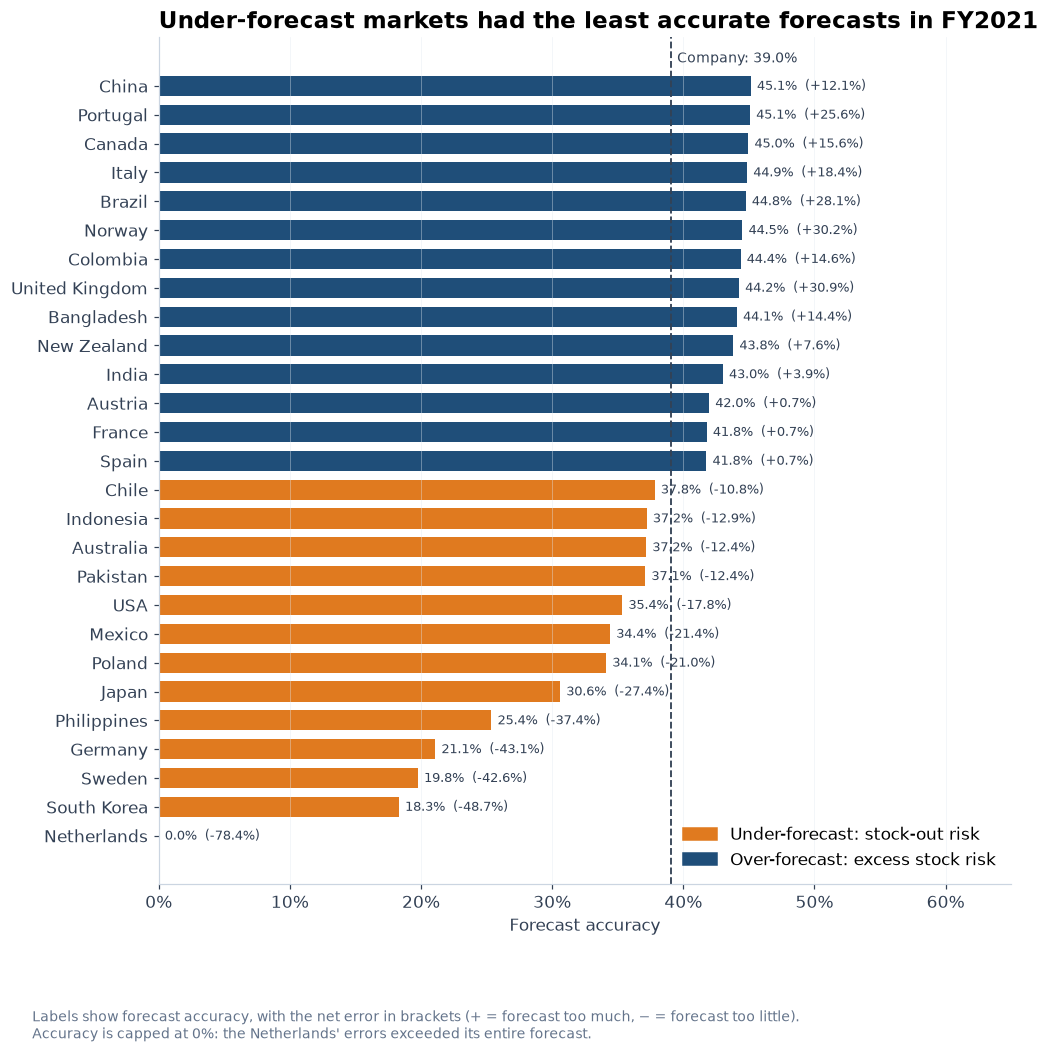

In [39]:
# Colour by direction: under-forecast (stock-out risk) vs over-forecast (excess stock risk)
colours = [HIGHLIGHT if e < 0 else NAVY for e in market_accuracy["net_error_pct"]]

fig, ax = plt.subplots(figsize=(10, 10))
bars = ax.barh(market_accuracy["market_name"], market_accuracy["accuracy_pct"],
               color=colours, height=0.7)

# Labels: accuracy, with the net error in brackets
ax.bar_label(bars,
             labels=[f"{a:.1f}%  ({e:+.1f}%)" for a, e in
                     zip(market_accuracy["accuracy_pct"], market_accuracy["net_error_pct"])],
             padding=4, fontsize=8.5, color=DARK_TEXT)

# Company accuracy as a reference line
ax.axvline(company_accuracy, color=DARK_TEXT, linestyle="--", linewidth=1.2)
ax.text(company_accuracy + 0.5, len(market_accuracy) - 0.3,
        f"Company: {company_accuracy:.1f}%", fontsize=9, color=DARK_TEXT, va="bottom")

ax.set_xlim(0, 65)
ax.set_xlabel("Forecast accuracy")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)

# Legend explaining the colours
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=HIGHLIGHT, label="Under-forecast: stock-out risk"),
                   Patch(color=NAVY, label="Over-forecast: excess stock risk")],
          loc="lower right")

ax.set_title("Under-forecast markets had the least accurate forecasts in FY2021")
fig.text(0.01, -0.03,
         "Labels show forecast accuracy, with the net error in brackets (+ = forecast too much, − = forecast too little).\n"
         "Accuracy is capped at 0%: the Netherlands' errors exceeded its entire forecast.",
         fontsize=9, color="#64748B")

save_chart(fig, "08_forecast_accuracy_by_market.png")
plt.show()

### Business insights - Chart 8

- **Under-forecast markets were the least accurate:** Every orange market (forecast too little) had accuracy of 37.8% or less, while every navy market (forecast too much) had 41.8% or more.
- **Several big markets were badly under-forecast:** South Korea had just 18.3% accuracy, with customers buying 48.7% more than forecast (−48.7%). The USA reached 35.4% (−17.8%), and the Philippines 25.4% (−37.4%).
- **The Netherlands' forecast gave no useful guidance:** Its accuracy is 0.0% (−78.4%), meaning its forecasting errors were larger than its entire forecast.
- **India, the largest market, was among the more accurate:** 43.0%, slightly over-forecast (+3.9%), above the company accuracy of 39.0%.
- **Some markets risk excess stock:** The United Kingdom (+30.9%) and Norway (+30.3%) were forecast about 30% higher than customers bought.

**What it means:** AtliQ's biggest forecasting problem is underestimating demand, and it's hitting important markets such as South Korea and the USA. Improving forecasts there would reduce the risk of stock-outs where it matters most.

## **Summary**

### Key findings:

1. **Rapid, profitable growth:** Net sales grew from USD 29M in FY2018 to USD 824M in FY2021, while gross margin stayed at about 36–41%. *(Chart 1)*
2. **Shift to high-value PCs:** Notebooks and desktops rose from 25.5% to 58.7% of net sales, so each unit sold brings in more revenue. *(Chart 2)*
3. **Strong seasonality:** Sales peak from October to December, nearly doubling in November and December. *(Chart 3)*
4. **Biggest market, below-average margin:** India, the largest market (USD 210.7M), earns less than the company's 36.5% margin. *(Chart 4)*
5. **Discounts drive profitability:** Customers receiving more deductions are less profitable; Flipkart the least, AtliQ's own stores the most. *(Chart 7)*
6. **Low forecast accuracy, shifting bias:** Accuracy stayed around 40%, with errors moving from over-forecasting to under-forecasting. *(Chart 5)*
7. **Under-forecasting hits big markets:** South Korea, the USA and the Philippines were among the least accurate, all forecast too low. *(Chart 8)*
8. **Under-forecasting is the bigger cost:** The profit at risk from forecasting too little exceeds the cost of holding excess stock, and the gap is growing. *(Chart 6)*

### Recommendations

- **Review discount and rebate agreements** with low-margin customers and markets, starting with Flipkart and India.
- **Grow the Direct channel**, AtliQ's most profitable route to customers.
- **Improve forecasting for fast-growing markets and customers**, where under-forecasting puts the most sales at risk.
- **Plan stock ahead of the October–December peak.**
- **Cut forecasts faster for declining categories** to avoid excess stock.